In [ ]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
data = pd.read_csv('/kaggle/input/veremi-extension-mendelydata/Vermi.csv')

In [ ]:
skewness = np.mean(data) 
print("Skewness:", skewness)

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3194808 entries, 0 to 3194807
Data columns (total 30 columns):
 #   Column        Dtype  
---  ------        -----  
 0   type          int64  
 1   sendTime      float64
 2   sender        int64  
 3   senderPseudo  int64  
 4   messageID     int64  
 5   class         int64  
 6   posx          float64
 7   posy          float64
 8   posz          float64
 9   posx_n        float64
 10  posy_n        float64
 11  posz_n        float64
 12  spdx          float64
 13  spdy          float64
 14  spdz          float64
 15  spdx_n        float64
 16  spdy_n        float64
 17  spdz_n        float64
 18  aclx          float64
 19  acly          float64
 20  aclz          float64
 21  aclx_n        float64
 22  acly_n        float64
 23  aclz_n        float64
 24  hedx          float64
 25  hedy          float64
 26  hedz          float64
 27  hedx_n        float64
 28  hedy_n        float64
 29  hedz_n        float64
dtypes: float64(25), in

In [4]:
data.columns

Index(['type', 'sendTime', 'sender', 'senderPseudo', 'messageID', 'class',
       'posx', 'posy', 'posz', 'posx_n', 'posy_n', 'posz_n', 'spdx', 'spdy',
       'spdz', 'spdx_n', 'spdy_n', 'spdz_n', 'aclx', 'acly', 'aclz', 'aclx_n',
       'acly_n', 'aclz_n', 'hedx', 'hedy', 'hedz', 'hedx_n', 'hedy_n',
       'hedz_n'],
      dtype='object')

In [5]:
def binarize_values(val):
    return 0 if val == 0 else 1

data['binaryClass'] = data['class'].apply(binarize_values)

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3194808 entries, 0 to 3194807
Data columns (total 31 columns):
 #   Column        Dtype  
---  ------        -----  
 0   type          int64  
 1   sendTime      float64
 2   sender        int64  
 3   senderPseudo  int64  
 4   messageID     int64  
 5   class         int64  
 6   posx          float64
 7   posy          float64
 8   posz          float64
 9   posx_n        float64
 10  posy_n        float64
 11  posz_n        float64
 12  spdx          float64
 13  spdy          float64
 14  spdz          float64
 15  spdx_n        float64
 16  spdy_n        float64
 17  spdz_n        float64
 18  aclx          float64
 19  acly          float64
 20  aclz          float64
 21  aclx_n        float64
 22  acly_n        float64
 23  aclz_n        float64
 24  hedx          float64
 25  hedy          float64
 26  hedz          float64
 27  hedx_n        float64
 28  hedy_n        float64
 29  hedz_n        float64
 30  binaryClass   int6

In [7]:
data['binaryClass'].value_counts()

binaryClass
0    1900539
1    1294269
Name: count, dtype: int64

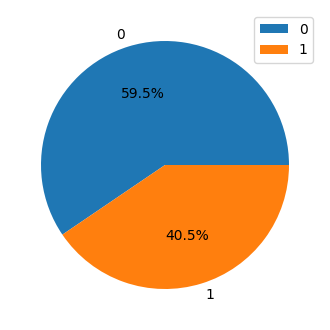

In [8]:
class_counts = data['binaryClass'].value_counts()
plt.figure(figsize=(4, 6))
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=0)
hfont = {'fontname':'serif', 'weight': 'bold'}
plt.legend()

plt.show()

In [9]:
data.head(5)

,type,sendTime,sender,senderPseudo,messageID,class,posx,posy,posz,posx_n,...,aclx_n,acly_n,aclz_n,hedx,hedy,hedz,hedx_n,hedy_n,hedz_n,binaryClass
0,4,72002.302942,130137,101301377,422013806,0,266.982401,32.336955,0.0,3.480882,...,0.000862,0.000862,0.0,-0.102790,0.994703,0.0,20.038218,17.541001,0.0,0
1,4,72003.302942,130137,101301377,422023410,0,266.827208,34.624145,0.0,3.546261,...,0.000107,0.001040,0.0,-0.099856,0.995002,0.0,20.441139,14.467283,0.0,0
2,4,72004.302942,130137,101301377,422032081,0,266.420297,38.836461,0.0,3.544045,...,0.000172,0.001661,0.0,-0.099856,0.995002,0.0,20.850473,11.941528,0.0,0
3,4,72005.302942,130137,101301377,422040712,0,268.912026,45.414229,0.0,3.340080,...,0.000171,0.001654,0.0,-0.100172,0.994970,0.0,21.323229,9.633965,0.0,0
4,4,72006.302942,130137,101301377,422052949,0,268.242276,53.729986,0.0,3.328872,...,0.000193,0.001852,0.0,-0.097105,0.995274,0.0,21.788034,7.824555,0.0,0


In [10]:
data.sort_values(by=['sender','sendTime'], inplace=True)
data.head(5)

,type,sendTime,sender,senderPseudo,messageID,class,posx,posy,posz,posx_n,...,aclx_n,acly_n,aclz_n,hedx,hedy,hedz,hedx_n,hedy_n,hedz_n,binaryClass
2365422,4,240.602763,9,1092,4184,0,265.105411,50.751262,0.0,4.714697,...,0.000534,0.000534,0.0,-0.093026,0.995664,0.0,6.791931,6.059563,0.0,0
2365423,4,241.602763,9,1092,4194,0,264.959604,53.058156,0.0,4.826480,...,0.000057,0.000552,0.0,-0.093026,0.995664,0.0,6.948994,4.856923,0.0,0
2365424,4,242.602763,9,1092,4204,0,264.331427,57.302385,0.0,5.004188,...,0.000122,0.001181,0.0,-0.098425,0.995144,0.0,7.138329,3.945763,0.0,0
2365425,4,243.602763,9,1092,4214,0,263.610633,63.710039,0.0,4.890198,...,0.000144,0.001109,0.0,-0.122430,0.992477,0.0,7.425940,3.276027,0.0,0
2365426,4,244.602763,9,1092,4224,0,262.621917,71.941010,0.0,4.968665,...,0.000211,0.000993,0.0,-0.137632,0.990483,0.0,7.736676,2.703289,0.0,0


In [11]:
data['shifted_posx'] = data.groupby('sender')['posx'].shift(1)
data['shifted_posy'] = data.groupby('sender')['posy'].shift(1)

In [12]:
data.head()

,type,sendTime,sender,senderPseudo,messageID,class,posx,posy,posz,posx_n,...,aclz_n,hedx,hedy,hedz,hedx_n,hedy_n,hedz_n,binaryClass,shifted_posx,shifted_posy
2365422,4,240.602763,9,1092,4184,0,265.105411,50.751262,0.0,4.714697,...,0.0,-0.093026,0.995664,0.0,6.791931,6.059563,0.0,0,NaN,NaN
2365423,4,241.602763,9,1092,4194,0,264.959604,53.058156,0.0,4.826480,...,0.0,-0.093026,0.995664,0.0,6.948994,4.856923,0.0,0,265.105411,50.751262
2365424,4,242.602763,9,1092,4204,0,264.331427,57.302385,0.0,5.004188,...,0.0,-0.098425,0.995144,0.0,7.138329,3.945763,0.0,0,264.959604,53.058156
2365425,4,243.602763,9,1092,4214,0,263.610633,63.710039,0.0,4.890198,...,0.0,-0.122430,0.992477,0.0,7.425940,3.276027,0.0,0,264.331427,57.302385
2365426,4,244.602763,9,1092,4224,0,262.621917,71.941010,0.0,4.968665,...,0.0,-0.137632,0.990483,0.0,7.736676,2.703289,0.0,0,263.610633,63.710039


In [13]:
def calculate_distance(row):
    if row.name == 0:
        return 0
    prev_pos = (row.shifted_posx, row.shifted_posy)
    curr_pos = (row.posx, row.posy)
    return np.sqrt((curr_pos[0] - prev_pos[0])**2 + (curr_pos[1] - prev_pos[1])**2)


In [14]:
data['distance'] = data.apply(calculate_distance, axis=1)

In [15]:
data['timedif'] = data.groupby('sender')['sendTime'].diff().fillna(0).astype(float)
data.head(5)

,type,sendTime,sender,senderPseudo,messageID,class,posx,posy,posz,posx_n,...,hedy,hedz,hedx_n,hedy_n,hedz_n,binaryClass,shifted_posx,shifted_posy,distance,timedif
2365422,4,240.602763,9,1092,4184,0,265.105411,50.751262,0.0,4.714697,...,0.995664,0.0,6.791931,6.059563,0.0,0,NaN,NaN,NaN,0.0
2365423,4,241.602763,9,1092,4194,0,264.959604,53.058156,0.0,4.826480,...,0.995664,0.0,6.948994,4.856923,0.0,0,265.105411,50.751262,2.311497,1.0
2365424,4,242.602763,9,1092,4204,0,264.331427,57.302385,0.0,5.004188,...,0.995144,0.0,7.138329,3.945763,0.0,0,264.959604,53.058156,4.290464,1.0
2365425,4,243.602763,9,1092,4214,0,263.610633,63.710039,0.0,4.890198,...,0.992477,0.0,7.425940,3.276027,0.0,0,264.331427,57.302385,6.448068,1.0
2365426,4,244.602763,9,1092,4224,0,262.621917,71.941010,0.0,4.968665,...,0.990483,0.0,7.736676,2.703289,0.0,0,263.610633,63.710039,8.290142,1.0


In [16]:
data.fillna(0, inplace=True)

In [17]:
def calculate_speed_magnitude(row):
    spdx = row.spdx
    spdy = row.spdy
    speed_magnitude = math.sqrt(spdx**2 + spdy**2)
    return speed_magnitude

In [18]:
data['speed'] = data.apply(calculate_speed_magnitude, axis=1)

In [19]:
data.drop(['shifted_posx','shifted_posy'],axis=1,inplace=True)

In [20]:
data.columns

Index(['type', 'sendTime', 'sender', 'senderPseudo', 'messageID', 'class',
       'posx', 'posy', 'posz', 'posx_n', 'posy_n', 'posz_n', 'spdx', 'spdy',
       'spdz', 'spdx_n', 'spdy_n', 'spdz_n', 'aclx', 'acly', 'aclz', 'aclx_n',
       'acly_n', 'aclz_n', 'hedx', 'hedy', 'hedz', 'hedx_n', 'hedy_n',
       'hedz_n', 'binaryClass', 'distance', 'timedif', 'speed'],
      dtype='object')

In [21]:
to_drop = ['aclx_n', 'acly_n', 'aclx', 'acly']
data.drop(to_drop, axis=1, inplace=True)

In [22]:
data.columns

Index(['type', 'sendTime', 'sender', 'senderPseudo', 'messageID', 'class',
       'posx', 'posy', 'posz', 'posx_n', 'posy_n', 'posz_n', 'spdx', 'spdy',
       'spdz', 'spdx_n', 'spdy_n', 'spdz_n', 'aclz', 'aclz_n', 'hedx', 'hedy',
       'hedz', 'hedx_n', 'hedy_n', 'hedz_n', 'binaryClass', 'distance',
       'timedif', 'speed'],
      dtype='object')

In [23]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression

X = data.drop(columns=['binaryClass','class'])  # Features
y = data['binaryClass']  # Target variable

# Perform correlation-based feature selection using SelectKBest with f_regression
selector = SelectKBest(score_func=f_regression, k=15)  # Select top 15 features
X_selected = selector.fit_transform(X, y)

# Get the selected feature names
selected_feature_names = X.columns[selector.get_support()]

print("Selected features:", selected_feature_names)


Selected features: Index(['senderPseudo', 'posx', 'posy', 'posx_n', 'posy_n', 'spdx', 'spdy',
       'spdx_n', 'spdy_n', 'hedx', 'hedy', 'hedx_n', 'distance', 'timedif',
       'speed'],
      dtype='object')


In [24]:
import pandas as pd
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Assuming 'data' is your existing DataFrame with features and target variable
X = data.drop(columns=['binaryClass'])  # Features
y = data['binaryClass']  # Target variable

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize the model (estimator)
estimator = LinearRegression()  # Number of features to select
rfe = RFE(estimator, n_features_to_select=15)

# Fit RFE
rfe.fit(X_train, y_train)

# Get selected features
selected_features = X.columns[rfe.support_]

print("Selected features:", selected_features)


Selected features: Index(['class', 'posx', 'posx_n', 'posy_n', 'spdx', 'spdy', 'spdx_n', 'spdy_n',
       'hedx', 'hedy', 'hedx_n', 'hedy_n', 'distance', 'timedif', 'speed'],
      dtype='object')


In [25]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split

# Assuming 'data' is your existing DataFrame with features and target variable
X = data.drop(columns=['class'])  # Features
y = data['class']  # Target variable

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and fit Lasso regression model
lasso = Lasso(alpha=0.1)  # You can adjust alpha (regularization strength) as needed
lasso.fit(X_train, y_train)

# Get selected features
selected_features = X.columns[lasso.coef_ != 0]

print("Selected features:", selected_features)

Selected features: Index(['sendTime', 'sender', 'senderPseudo', 'messageID', 'posx', 'posy',
       'spdx', 'spdy', 'hedx_n', 'hedy_n', 'binaryClass', 'distance',
       'timedif', 'speed'],
      dtype='object')


/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.182e+06, tolerance: 1.014e+04
  model = cd_fast.enet_coordinate_descent(


In [26]:
selected_features = [ 'posx','posy','posx_n', 'posy_n', 'spdx', 'spdy', 'spdx_n', 'spdy_n',
       'hedx', 'hedy', 'hedx_n', 'hedy_n', 'distance', 'timedif', 'speed']
df = data[selected_features].copy()


/tmp/ipykernel_33/2094188295.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['distance'],hist=True)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<Axes: xlabel='distance', ylabel='Density'>

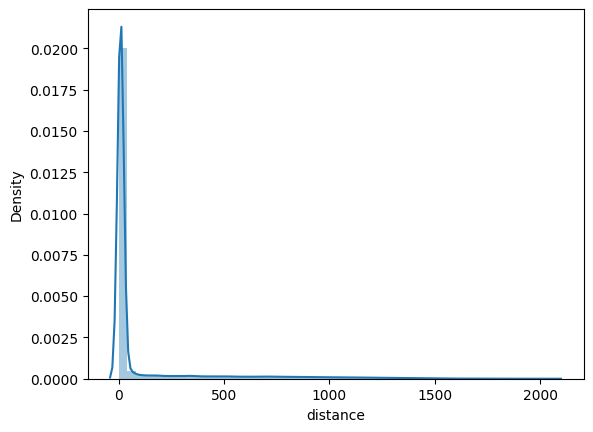

In [28]:
sns.distplot(df['distance'],hist=True)

In [29]:
skewness = np.mean(df) 
print("Skewness:", skewness)

Skewness: 95.0726831801591


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# Fit scaler to your data and transform it
scaled_data = scaler.fit_transform(dfs)

# Convert the scaled data back to a DataFrame
df = pd.DataFrame(scaled_data, columns=dfs.columns)

# Now df_scaled contains your DataFrame with scaled values
print(df)

In [30]:
df['class']=data['class']
df['binaryClass']=data['binaryClass']

In [31]:
df.head()

,posx,posy,posx_n,posy_n,spdx,spdy,spdx_n,spdy_n,hedx,hedy,hedx_n,hedy_n,distance,timedif,speed,class,binaryClass
2365422,265.105411,50.751262,4.714697,4.591569,-0.106863,1.034114,-0.000000,-0.000000,-0.093026,0.995664,6.791931,6.059563,0.000000,0.0,1.039621,0,0
2365423,264.959604,53.058156,4.826480,4.516395,-0.335474,3.246444,0.000057,-0.000552,-0.093026,0.995664,6.948994,4.856923,2.311497,1.0,3.263731,0,0
2365424,264.331427,57.302385,5.004188,4.535059,-0.604297,5.324067,0.000179,-0.001734,-0.098425,0.995144,7.138329,3.945763,4.290464,1.0,5.358252,0,0
2365425,263.610633,63.710039,4.890198,4.370803,-0.999298,7.184181,0.000323,-0.002843,-0.122430,0.992477,7.425940,3.276027,6.448068,1.0,7.253347,0,0
2365426,262.621917,71.941010,4.968665,4.350376,-1.409192,9.105838,0.000534,-0.003836,-0.137632,0.990483,7.736676,2.703289,8.290142,1.0,9.214234,0,0


In [ ]:
plt.figure(figsize=(15, 10))
for i, feature in enumerate(selected_features):
    plt.subplot(4, 5, i + 1)  # Adjust subplot grid as per the number of features
    sns.histplot(df[feature], kde=True)
    plt.title(feature)
    plt.xlabel('')
    plt.ylabel('Density')
plt.tight_layout()
plt.show()

In [32]:
df.head()

,posx,posy,posx_n,posy_n,spdx,spdy,spdx_n,spdy_n,hedx,hedy,hedx_n,hedy_n,distance,timedif,speed,class,binaryClass
2365422,265.105411,50.751262,4.714697,4.591569,-0.106863,1.034114,-0.000000,-0.000000,-0.093026,0.995664,6.791931,6.059563,0.000000,0.0,1.039621,0,0
2365423,264.959604,53.058156,4.826480,4.516395,-0.335474,3.246444,0.000057,-0.000552,-0.093026,0.995664,6.948994,4.856923,2.311497,1.0,3.263731,0,0
2365424,264.331427,57.302385,5.004188,4.535059,-0.604297,5.324067,0.000179,-0.001734,-0.098425,0.995144,7.138329,3.945763,4.290464,1.0,5.358252,0,0
2365425,263.610633,63.710039,4.890198,4.370803,-0.999298,7.184181,0.000323,-0.002843,-0.122430,0.992477,7.425940,3.276027,6.448068,1.0,7.253347,0,0
2365426,262.621917,71.941010,4.968665,4.350376,-1.409192,9.105838,0.000534,-0.003836,-0.137632,0.990483,7.736676,2.703289,8.290142,1.0,9.214234,0,0


In [33]:
data['binaryClass'].value_counts()

binaryClass
0    1900539
1    1294269
Name: count, dtype: int64

In [34]:
to_drop=['class','binaryClass']
X=data.drop(to_drop,axis=1)
y=data['binaryClass']

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [36]:
DT = DecisionTreeClassifier()
DT.fit(X_train, y_train)

DecisionTreeClassifier()

In [37]:
DT_pred = DT.predict(X_test)
print(classification_report(y_test,DT_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98    570474
           1       0.97      0.97      0.97    387969

    accuracy                           0.98    958443
   macro avg       0.98      0.98      0.98    958443
weighted avg       0.98      0.98      0.98    958443



In [38]:
RF = RandomForestClassifier()
RF.fit(X_train, y_train)

RandomForestClassifier()

In [39]:
RF_pred = RF.predict(X_test)

print(classification_report(y_test,RF_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99    570474
           1       1.00      0.97      0.98    387969

    accuracy                           0.99    958443
   macro avg       0.99      0.98      0.99    958443
weighted avg       0.99      0.99      0.99    958443



In [40]:
ET = ExtraTreesClassifier()
ET.fit(X_train, y_train)

ET_pred = ET.predict(X_test)
print(classification_report(y_test,ET_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99    570474
           1       0.99      0.97      0.98    387969

    accuracy                           0.98    958443
   macro avg       0.99      0.98      0.98    958443
weighted avg       0.98      0.98      0.98    958443



In [41]:
import xgboost as xgb
from xgboost import XGBClassifier

xgb = xgb.XGBClassifier()
xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)
print(classification_report(y_test,xgb_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    570474
           1       1.00      0.95      0.97    387969

    accuracy                           0.98    958443
   macro avg       0.98      0.97      0.98    958443
weighted avg       0.98      0.98      0.98    958443



In [42]:
df['triClass'] = df['class'].map({0: 0, 16: 1, 15: 1, 18: 1, 19: 1, 3: 1, 1: 1, 2: 1, 4: 1})
df['triClass'] = df['triClass'].fillna(2)
df['triClass'] = df['triClass'].astype(int)

In [43]:
df['triClass'].value_counts()

triClass
0    1900539
1     647296
2     646973
Name: count, dtype: int64

In [44]:
to_drop=['class','binaryClass','triClass']
X=df.drop(to_drop,axis=1)
y=df['triClass']

In [45]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)
X_train_unsam, y_train_unsam = rus.fit_resample(X_train, y_train)


In [46]:
from collections import Counter

print("The number of classes after fit {}".format(Counter(y_train_unsam)))

The number of classes after fit Counter({0: 453010, 1: 453010, 2: 453010})


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')  
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',  
              metrics=['accuracy'])

model.fit(X_train, y_train, epochs=20, batch_size=64, validation_split=0.2)
test_loss, test_acc = model.evaluate(X_test, y_test)
print('Test accuracy:', test_acc)


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.layers import Bidirectional, LSTM, Dense, Embedding

# Assuming df contains the data and 'class', 'binaryClass', 'triClass' are columns to drop
to_drop = ['class', 'binaryClass', 'triClass']
X = df.drop(to_drop, axis=1)
y = df['triClass']

# Preprocessing input features
max_sequence_length = 100  # Set the maximum length of sequences
vocab_size = 10000  # Set the vocabulary size

X = np.clip(X, 0, vocab_size - 1)

sequences = X.values

# Pad sequences to make them of uniform length
sequences = pad_sequences(sequences, maxlen=max_sequence_length)

# Preprocessing target variable
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Splitting the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(sequences, y, test_size=0.2, random_state=42)

# Define the BiLSTM model
embedding_dim = 1006
hidden_units = 64

model = Sequential()
model.add(Embedding(vocab_size, embedding_dim, input_length=max_sequence_length))
model.add(Bidirectional(LSTM(hidden_units)))
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(X_train, y_train, epochs=3, batch_size=64, validation_data=(X_test, y_test))

# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)
print(f'Test Loss: {loss}')
print(f'Test Accuracy: {accuracy}')


In [ ]:
''''from sklearn.neighbors import KNeighborsClassifier

knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_unsam,y_train_unsam)
y_pred=knn.predict(X_test)

print(classification_report(y_test,y_pred))''''

In [47]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


params = {
    'objective': 'binary', 
    'metric': 'binary_error',
    'num_leaves': 31,  
    'learning_rate': 0.05,  
    'feature_fraction': 0.9,  
    'bagging_fraction': 0.8,  
    'bagging_freq': 5,  
    'verbose': 0  
}

train_data = lgb.Dataset(X_train, label=y_train)
test_data = lgb.Dataset(X_test, label=y_test)

num_round = 100  
bst = lgb.train(params, train_data, num_round, valid_sets=[test_data])

y_pred = bst.predict(X_test, num_iteration=bst.best_iteration)
y_pred_binary = [1 if pred > 0.5 else 0 for pred in y_pred]
accuracy = accuracy_score(y_test, y_pred_binary)
print(f'Accuracy: {accuracy}')

Accuracy: 0.786225158929639


In [48]:
RF = RandomForestClassifier()
RF.fit(X_train_unsam, y_train_unsam)

RF_pred = RF.predict(X_test)
print(classification_report(y_test,RF_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98    570474
           1       0.95      0.96      0.95    194006
           2       0.94      0.88      0.91    193963

    accuracy                           0.96    958443
   macro avg       0.95      0.94      0.95    958443
weighted avg       0.96      0.96      0.96    958443



In [49]:
ET = ExtraTreesClassifier()
ET.fit(X_train_unsam, y_train_unsam)

ET_pred = ET.predict(X_test)
print(classification_report(y_test,ET_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98    570474
           1       0.93      0.96      0.95    194006
           2       0.94      0.86      0.90    193963

    accuracy                           0.96    958443
   macro avg       0.95      0.94      0.94    958443
weighted avg       0.96      0.96      0.96    958443



In [50]:
import xgboost as xgb
from xgboost import XGBClassifier

xgb = xgb.XGBClassifier()
xgb.fit(X_train_unsam, y_train_unsam)

xgb_pred = xgb.predict(X_test)
print(classification_report(y_test,xgb_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98    570474
           1       0.92      0.91      0.91    194006
           2       0.94      0.83      0.88    193963

    accuracy                           0.95    958443
   macro avg       0.94      0.91      0.92    958443
weighted avg       0.95      0.95      0.94    958443



In [51]:
DT = DecisionTreeClassifier()
DT.fit(X_train_unsam, y_train_unsam)
DT_pred = DT.predict(X_test)
print(classification_report(y_test,DT_pred))

              precision    recall  f1-score   support

           0       0.97      0.93      0.95    570474
           1       0.92      0.94      0.93    194006
           2       0.79      0.89      0.84    193963

    accuracy                           0.92    958443
   macro avg       0.90      0.92      0.91    958443
weighted avg       0.93      0.92      0.92    958443



In [ ]:
from sklearn.svm import SVC
svm_classifier = SVC(kernel='linear', C=1.0, random_state=42)

svm_classifier.fit(X_train_unsam, y_train_unsam)
sv_pred = svm_classifier.predict(X_test)
accuracy = accuracy_score(y_test, sv_pred)
print("Accuracy:", accuracy)

In [ ]:
print(classification_report(y_test,DT_pred))

In [ ]:
len(X_train)

In [ ]:
X_train_df = pd.DataFrame(X_train)
y_train_df = pd.DataFrame(y_train)
train_df = pd.concat([X_train_df, y_train_df], axis=1)

In [ ]:
train_df.head(5)

In [ ]:
X1_minority = train_df[train_df['triClass'] == 1].drop('triClass', axis=1).values
X2_minority = train_df[train_df['triClass'] == 2].drop('triClass', axis=1).values

majority_class = train_df[train_df['triClass'] == 0].drop('triClass', axis=1).values

In [ ]:
len(X1_minority)

In [ ]:
sampled_X1_minority_df = pd.DataFrame(sampled_X1_minority)
sampled_X2_minority_df = pd.DataFrame(sampled_X2_minority)

sampled_X1_minority_df['target'] = 1
sampled_X2_minority_df['target'] = 2

minority_df = pd.concat([sampled_X1_minority_df, sampled_X2_minority_df])

majority_class_df = pd.DataFrame(majority_class_data)
majority_class_df['target'] = 0

In [ ]:
combined_df = pd.concat([minority_df, majority_class_df])

# Shuffle the combined DataFrame
combined_df = combined_df.sample(frac=1, random_state=42).reset_index(drop=True)